# Delhi Air Quality - EDA & Visualisations

#### Step 1 — Import the required libraries

In [32]:
# What this cell does: Import pandas for tables, NumPy for numerical calculations, Matplotlib for charts, Path for file locations, and display for readable notebook outputs.
# Expected output: Libraries load, default chart settings are configured and the visualizations folder is ready.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
# Configure or display the visualization.
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.2})
# Import a helper for generating all station pairs.
from itertools import combinations

# Locate the project root (works whether Jupyter starts in notebooks/ or in the repo root).
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
# Folder where every chart from this notebook is saved.
FIG_DIR = PROJECT_ROOT / "visualizations"
# Create the folder if it does not exist yet.
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Save the current chart as a PNG in the visualizations folder (call before plt.show()).
def save_fig(filename, fig=None):
    if fig is None:
        fig = plt.gcf()
    path = FIG_DIR / f"{filename}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Chart saved: visualizations/{path.name}")

#### Step 2 — Load the cleaned and standardised dataset

In [33]:
# Define the CSV file location (daily dataset exported by the data-cleaning notebook).
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "Delhi_Air_Quality_Daily_2025.csv"
# Stop early with a clear message if the file is missing.
assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"
# Load the CSV into a DataFrame and parse dates.
df = pd.read_csv(DATA_PATH, parse_dates=["date"])
# Preview the first five rows.
display(df.head())
# Show the number of rows and columns.
print("Dataset shape:", df.shape)

,date,location,aqi_index,pm2_5,pm10,co,no2,temp_c,humidity,pressure_mb,windspeed_kph
0,2025-01-01,Anand Vihar,200.000000,145.175000,147.837500,1535.500000,34.616667,11.004167,89.958333,994.362500,5.512500
1,2025-01-02,Anand Vihar,196.541667,145.370833,149.341667,1701.500000,33.241667,12.370833,86.375000,993.575000,6.025000
2,2025-01-03,Anand Vihar,201.875000,158.791667,168.179167,2246.708333,54.083333,12.525000,89.333333,993.375000,3.825000
3,2025-01-04,Anand Vihar,213.833333,166.491667,176.479167,2654.333333,76.295833,12.633333,89.916667,991.325000,3.808333
4,2025-01-05,Anand Vihar,217.583333,158.225000,163.804167,1688.541667,44.412500,12.029167,90.041667,991.479167,5.591667


Dataset shape: (2190, 11)


#### Step 3 — Review the dataset structure and descriptive statistics

In [34]:
# Inspect column types and non-missing values.
df.info()
# Display the resulting table.
display(df.describe(include="all").T)
# Display the calculated result for interpretation.
# Display the resulting table.
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
display(df.groupby("location").agg(records=("date", "size"), days=("date", "nunique")))

<class 'pandas.DataFrame'>
RangeIndex: 2190 entries, 0 to 2189
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           2190 non-null   datetime64[us]
 1   location       2190 non-null   str           
 2   aqi_index      2190 non-null   float64       
 3   pm2_5          2190 non-null   float64       
 4   pm10           2190 non-null   float64       
 5   co             2190 non-null   float64       
 6   no2            2190 non-null   float64       
 7   temp_c         2190 non-null   float64       
 8   humidity       2190 non-null   float64       
 9   pressure_mb    2190 non-null   float64       
 10  windspeed_kph  2190 non-null   float64       
dtypes: datetime64[us](1), float64(9), str(1)
memory usage: 188.3 KB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,2190,NaN,NaN,NaN,2025-07-02 00:00:00,2025-01-01 00:00:00,2025-04-02 00:00:00,2025-07-02 00:00:00,2025-10-01 00:00:00,2025-12-31 00:00:00,NaN
location,2190,6,Anand Vihar,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aqi_index,2190.0,NaN,NaN,NaN,287.364212,58.958333,152.041667,170.354167,246.041667,2443.791667,320.791652
pm2_5,2190.0,NaN,NaN,NaN,89.542432,15.25,56.5,77.647917,107.845833,324.829167,46.561204
pm10,2190.0,NaN,NaN,NaN,300.4627,15.654167,94.479167,159.3625,339.6625,2833.716667,370.998252
co,2190.0,NaN,NaN,NaN,863.844273,303.333333,550.9375,701.354167,1041.125,3184.25,448.72255
no2,2190.0,NaN,NaN,NaN,35.442757,9.616667,23.545833,30.727083,43.375,103.766667,17.277333
temp_c,2190.0,NaN,NaN,NaN,25.024406,10.591667,18.938542,27.2375,30.165625,37.95,6.663774
humidity,2190.0,NaN,NaN,NaN,62.28594,10.208333,50.177083,63.666667,78.40625,93.541667,19.106842
pressure_mb,2190.0,NaN,NaN,NaN,983.162635,969.016667,977.584375,983.289583,988.925,996.470833,6.56042


Date range: 2025-01-01 to 2025-12-31


,records,days
location,,
Anand Vihar,365,365
Connaught Place,365,365
Dwarka,365,365
IGI Airport,365,365
Okhla Phase III,365,365
Rohini,365,365


#### Step 4 — Verify completeness, duplicate keys, and coverage

In [35]:
# Display the calculated result for interpretation.
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
date             0
location         0
aqi_index        0
pm2_5            0
pm10             0
co               0
no2              0
temp_c           0
humidity         0
pressure_mb      0
windspeed_kph    0
dtype: int64


#### Step 5 — Detect identical daily station profiles

In [36]:
# What this cell does: Align each pair of locations by date and count days with identical AQI and identical full measurement records.
# Expected output: Pairwise comparison table and a caution message.

# Select measurements used for station comparisons.
measure_cols = ["aqi_index", "pm2_5", "pm10", "co", "no2", "temp_c", "humidity", "pressure_mb", "windspeed_kph"]
# Build one date-indexed table for each location.
series = {loc: part.set_index("date")[measure_cols].sort_index() for loc, part in df.groupby("location")}
# Prepare a list to collect pairwise comparison results.
comparisons = []
# Compare every pair of locations on dates they share.
for a, b in combinations(series, 2):
    left, right = series[a].align(series[b], join="inner", axis=0)
    identical_days = left.eq(right).all(axis=1).sum()
    identical_aqi_days = left["aqi_index"].eq(right["aqi_index"]).sum()
    comparisons.append({"location_a": a, "location_b": b, "shared_days": len(left), "identical_AQI_days": int(identical_aqi_days), "identical_days_all_measurements": int(identical_days), "same_AQI_profile": bool(len(left) and identical_aqi_days == len(left) and len(left) == len(series[a]) == len(series[b]))})
# Convert the collected comparisons into a table.
comparison_df = pd.DataFrame(comparisons)
# Display the resulting table.
display(comparison_df.sort_values("identical_AQI_days", ascending=False))
# Display the calculated result for interpretation.
print("CAUTION: Identical AQI series are not independent AQI evidence; other measurements may differ.")

,location_a,location_b,shared_days,identical_AQI_days,identical_days_all_measurements,same_AQI_profile
0,Anand Vihar,Connaught Place,365,365,0,True
4,Anand Vihar,Rohini,365,365,0,True
8,Connaught Place,Rohini,365,365,0,True
12,IGI Airport,Okhla Phase III,365,365,0,True
10,Dwarka,Okhla Phase III,365,365,0,True
9,Dwarka,IGI Airport,365,365,0,True
1,Anand Vihar,Dwarka,365,0,0,False
6,Connaught Place,IGI Airport,365,0,0,False
5,Connaught Place,Dwarka,365,0,0,False
3,Anand Vihar,Okhla Phase III,365,0,0,False


CAUTION: Identical AQI series are not independent AQI evidence; other measurements may differ.


#### Step 6 — Define AQI bands and flag values above the CPCB range

In [37]:
# What this cell does: Assign each AQI observation to a severity band, calculate counts and percentages, and flag readings above 500.
# Expected output: AQI band summary, number of values above 500, and maximum observed AQI.

# Define the numerical cutoffs for AQI categories.
bins = [-np.inf, 50, 100, 200, 300, 400, 500, np.inf]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very poor", "Severe", "Above 500 (flag)"]
# Assign each observation to an AQI category.
df["aqi_band"] = pd.cut(df["aqi_index"], bins=bins, labels=labels, right=True)
# Count records in each category, including empty categories.
band_counts = df["aqi_band"].value_counts().reindex(labels, fill_value=0)
# Convert counts into a summary with percentages.
band_summary = pd.DataFrame({"records": band_counts, "percent": (band_counts / len(df) * 100).round(1)})
# Display the resulting table.
display(band_summary)
# Display the calculated result for interpretation.
print("Values >500:", (df["aqi_index"] > 500).sum())
# Report the maximum AQI observed.
print("Maximum AQI:", round(df["aqi_index"].max(), 1))

,records,percent
aqi_band,,
Good,0,0.0
Satisfactory,87,4.0
Moderate,1386,63.3
Poor,285,13.0
Very poor,84,3.8
Severe,60,2.7
Above 500 (flag),288,13.2


Values >500: 288
Maximum AQI: 2443.8


#### Step 7 — Visualise AQI record distribution

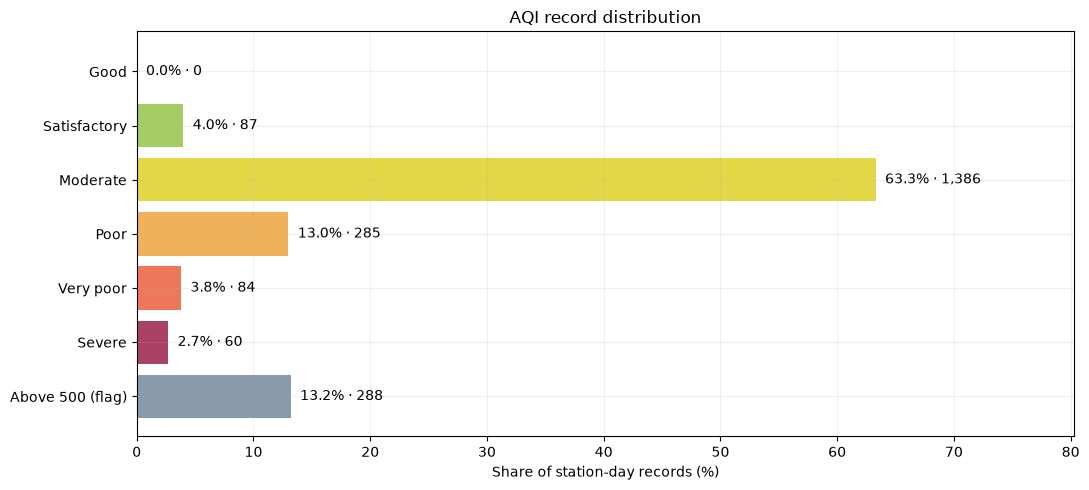

In [38]:
# What this cell does: Draw a horizontal bar for each AQI band and label each bar with its share and count.
# Expected output: Horizontal bar chart of AQI band percentages. The chart is saved to visualizations/.

# Create the chart and its primary axis.
fig, ax = plt.subplots(figsize=(11, 5))
# Calculate or prepare an intermediate analysis result.
colors = ["#86bd5a", "#a4ce63", "#e4d747", "#efb15a", "#ed785e", "#aa4265", "#899baa"]
# Calculate or prepare an intermediate analysis result.
bars = ax.barh(band_summary.index, band_summary["percent"], color=colors)
# Configure or display the visualization.
ax.invert_yaxis()
# Repeat the following calculation for each item.
for bar, pct, count in zip(bars, band_summary["percent"], band_summary["records"]):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height()/2, f"{pct:.1f}% · {count:,}", va="center")
# Set chart labels and title.
ax.set(xlabel="Share of station-day records (%)", title="AQI record distribution")
# Configure or display the visualization.
ax.set_xlim(0, max(80, band_summary["percent"].max()+17))
# Adjust spacing and render the chart.
plt.tight_layout()
# Save the chart to the visualizations folder.
save_fig("eda_01_aqi_band_distribution")
# Display the chart in the notebook.
plt.show()

#### Observations:
1. The majority of AQI observations (63.3%) fall under the Moderate category, representing 1,386 out of 2,190 records.
2. The Poor category accounts for 13.0%, while Very Poor and Severe account for 3.8% and 2.7%, respectively.
3. Only 4.0% of observations fall under Satisfactory, and no observations are classified as Good.
4. A significant 13.2% of records have AQI values exceeding 500, which are flagged for further investigation.

#### Step 8 — Examine out-of-range AQI records

In [39]:
# What this cell does: Create a Boolean flag for AQI above 500, summarize these by location, and count their occurrence by month name.
# Expected output: Location-level counts, overall share, and monthly counts of flagged records.

# Calculate or prepare an intermediate analysis result.
df["above_500"] = df["aqi_index"] > 500
# Display the resulting table.
display(df.groupby("location").agg(records=("aqi_index", "size"), above_500=("above_500", "sum"), maximum_aqi=("aqi_index", "max")))
# Display the calculated result for interpretation.
print("Out-of-range share:", f"{df['above_500'].mean():.1%}")
# Display the resulting table.
display(df.loc[df["above_500"]].groupby(df.loc[df["above_500"], "date"].dt.month_name()).size().rename("above_500_records"))

,records,above_500,maximum_aqi
location,,,
Anand Vihar,365,12,726.458333
Connaught Place,365,12,726.458333
Dwarka,365,84,2443.791667
IGI Airport,365,84,2443.791667
Okhla Phase III,365,84,2443.791667
Rohini,365,12,726.458333


Out-of-range share: 13.2%


date
April     78
August    15
June      51
March     69
May       75
Name: above_500_records, dtype: int64

#### Observations:
1. A total of 288 observations, representing 13.2% of the dataset, exceed AQI 500.
2. Dwarka, IGI Airport, and Okhla Phase III each contain 84 flagged records.
3. Anand Vihar, Connaught Place, and Rohini each contain 12 flagged records.
4. The maximum recorded AQI is approximately 2,443.8, which is substantially above the upper limit of the standard Indian AQI reporting scale.
   
Conclusion: The out-of-range values and identical location profiles represent important data-quality limitations that must be addressed before using these results for public-health recommendations.

#### Step 9 — Create analytical profiles A and B

In [40]:
# What this cell does: Map the six location labels to Profile A or Profile B and extract the month from each date.
# Expected output: A table showing which locations belong to each profile.

# Calculate or prepare an intermediate analysis result.
profile_map = {"Anand Vihar": "Profile A", "Connaught Place": "Profile A", "Rohini": "Profile A", "Dwarka": "Profile B", "IGI Airport": "Profile B", "Okhla Phase III": "Profile B"}
# Calculate or prepare an intermediate analysis result.
df["profile"] = df["location"].map(profile_map)
# Calculate or prepare an intermediate analysis result.
df["month"] = df["date"].dt.month
assert df["profile"].notna().all(), "Unexpected location labels; review profile mapping"
# Display the resulting table.
display(df.groupby("profile")["location"].unique().to_frame("locations"))

,locations
profile,
Profile A,"[Anand Vihar, Connaught Place, Rohini]"
Profile B,"[Dwarka, IGI Airport, Okhla Phase III]"


#### Step 10 — Plot monthly AQI median and out-of-range record counts

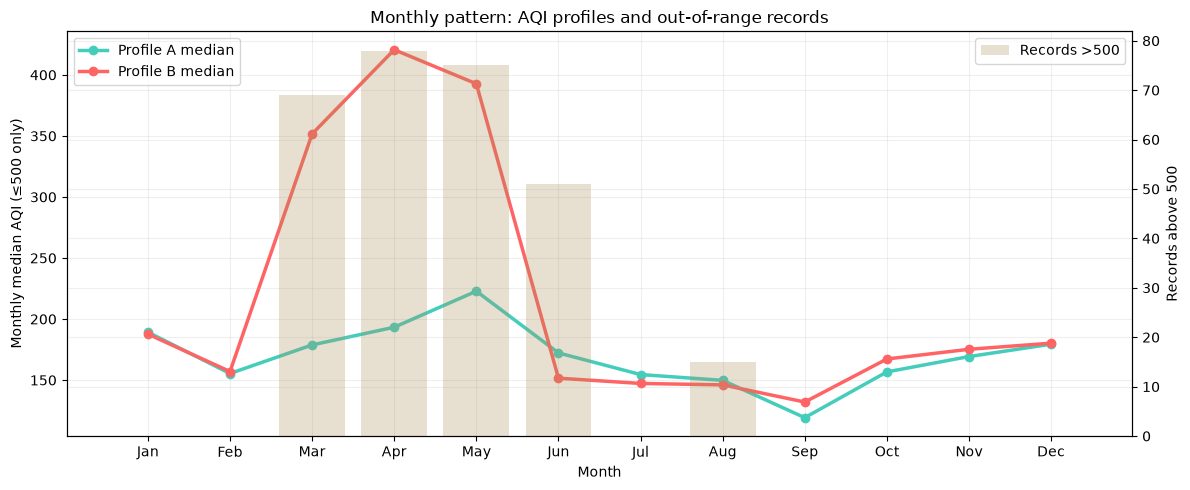

Profile B peak in-range monthly median: 420.6 in month 4


In [41]:
# What this cell does: Keep one row per date and profile, exclude AQI values above 500 from the median series, and plot monthly medians alongside flagged record counts.
# Expected output: Dual-axis monthly chart and the peak in-range Profile B median. The chart is saved to visualizations/.

# Keep one observation per date and analytical profile.
daily_profiles = df.drop_duplicates(["date", "profile"]).copy()
# Exclude AQI readings outside the 0–500 range for median trends.
in_range = daily_profiles.loc[daily_profiles["aqi_index"].between(0, 500)]
# Calculate median AQI for each month and profile.
monthly_median = in_range.groupby(["month", "profile"])["aqi_index"].median().unstack()
# Count records above 500 for each month.
monthly_flags = df.groupby("month")["above_500"].sum().reindex(range(1,13), fill_value=0)
# Create the chart and its primary axis.
fig, ax = plt.subplots(figsize=(12, 5))
# Add a second vertical axis for a different measurement.
ax2 = ax.twinx()
# Draw the monthly counts as bars.
ax2.bar(monthly_flags.index, monthly_flags.values, color="#aa8d58", alpha=.28, label="Records >500")
# Draw a separate trend line for each profile.
for profile, color in [("Profile A", "#45cdbc"), ("Profile B", "#ff6464")]:
    ax.plot(monthly_median.index, monthly_median[profile], marker="o", linewidth=2.5, color=color, label=f"{profile} median")
# Set chart labels and title.
ax.set(xlabel="Month", ylabel="Monthly median AQI (≤500 only)", title="Monthly pattern: AQI profiles and out-of-range records")
# Label months along the horizontal axis.
ax.set_xticks(range(1,13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
# Label the secondary vertical axis.
ax2.set_ylabel("Records above 500")
# Display chart legends.
ax.legend(loc="upper left"); ax2.legend(loc="upper right")
# Adjust spacing and render the chart.
plt.tight_layout()
# Save the chart to the visualizations folder.
save_fig("eda_02_monthly_aqi_profiles")
# Display the chart in the notebook.
plt.show()
# Display the calculated result for interpretation.
print("Profile B peak in-range monthly median:", round(monthly_median["Profile B"].max(), 1), "in month", monthly_median["Profile B"].idxmax())

#### Observations:
1. AQI levels vary substantially throughout the year, indicating a seasonal pattern in the dataset.
2. Profile B reaches its highest monthly median in-range AQI of approximately 420.6 during April.
3. Out-of-range AQI values occur mainly during March, April, May, and June, with a smaller number in August.
4. April records the highest number of flagged observations (78), followed by May (75), March (69), June (51), and August (15).
5. The seasonal variation suggests that pollution patterns may be associated with changing environmental conditions, although this analysis does not establish their causes.
   
Conclusion: The dataset shows a pronounced increase in AQI during spring and early summer, particularly for Profile B. The unusual high values require verification before drawing conclusions about actual seasonal air quality in Delhi.

#### Step 11 — Compare location-level AQI (with a warning)

,mean,median,max
location,,,
Anand Vihar,194.5,165.8,726.5
Connaught Place,194.5,165.8,726.5
Rohini,194.5,165.8,726.5
Dwarka,380.3,179.1,2443.8
IGI Airport,380.3,179.1,2443.8
Okhla Phase III,380.3,179.1,2443.8


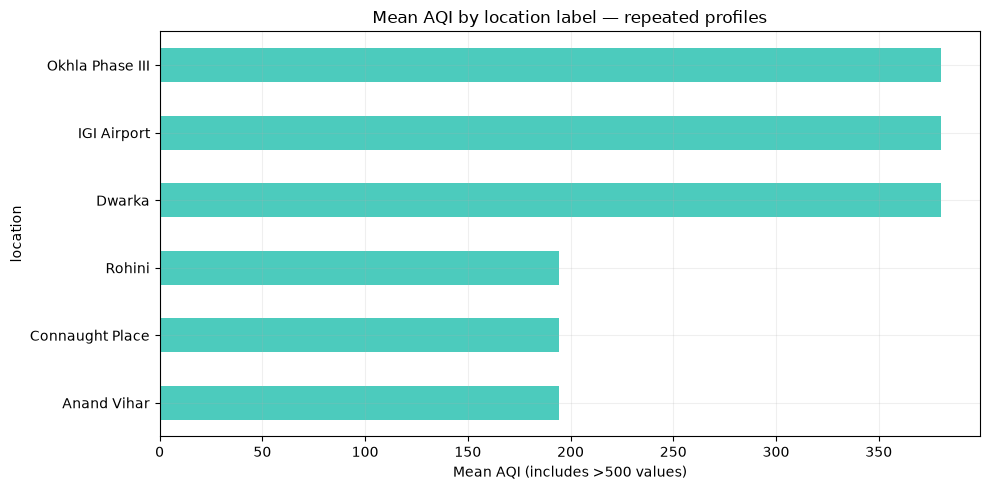

In [42]:
# What this cell does: Compute mean, median, and maximum AQI per location and plot mean AQI by label.
# Expected output: Location statistics and a horizontal mean-AQI chart. The chart is saved to visualizations/.

# Calculate or prepare an intermediate analysis result.
location_stats = df.groupby("location")["aqi_index"].agg(["mean", "median", "max"]).sort_values("mean")
# Display the resulting table.
display(location_stats.round(1))
# Calculate or prepare an intermediate analysis result.
ax = location_stats["mean"].plot(kind="barh", figsize=(10, 5), color="#4ccbbd", title="Mean AQI by location label — repeated profiles")
# Configure or display the visualization.
ax.set_xlabel("Mean AQI (includes >500 values)")
# Adjust spacing and render the chart.
plt.tight_layout()
# Save the chart to the visualizations folder.
save_fig("eda_03_mean_aqi_by_location")
# Display the chart in the notebook.
plt.show()
# Display the calculated result for interpretation.
print("Warning: identical labels do not establish independent location rankings.")

#### Observations:
1. Dwarka, IGI Airport, and Okhla Phase III show identical average AQI values of approximately 380.3.
2. Anand Vihar, Connaught Place, and Rohini show identical average AQI values of approximately 194.5.
3. The maximum AQI reaches approximately 2,443.8 in the first group and 726.5 in the second group.
4. The identical values within each group reflect duplicated analytical profiles rather than independently confirmed station measurements.
5. Therefore, the chart cannot reliably establish which individual monitoring location experiences the worst air quality.
   
Conclusion: Although the chart displays differences between two groups of locations, these results should not be used to rank individual Delhi monitoring stations until independent station data is verified.

#### Step 12 — Calculate Pearson and Spearman correlations

In [43]:
# What this cell does: Calculate Pearson linear correlation and Spearman rank correlation between AQI and each pollutant or weather variable.
# Expected output: Correlation table with two coefficients per variable.

# List the pollutant and weather variables to compare with AQI.
predictors = ["pm10", "pm2_5", "co", "no2", "humidity", "windspeed_kph", "temp_c", "pressure_mb"]
# Calculate Pearson and Spearman correlations for each variable.
corr_table = pd.DataFrame({
    "Pearson r": [df["aqi_index"].corr(df[c], method="pearson") for c in predictors],
    "Spearman rho": [df["aqi_index"].corr(df[c], method="spearman") for c in predictors]
# Calculate or prepare an intermediate analysis result.
}, index=predictors)
# Display the resulting table.
display(corr_table.round(3))

,Pearson r,Spearman rho
pm10,0.930,0.793
pm2_5,0.623,0.835
co,-0.200,0.065
no2,-0.261,-0.024
humidity,-0.414,-0.438
windspeed_kph,0.330,0.012
temp_c,0.225,0.081
pressure_mb,-0.148,0.082


#### Step 13 — Plot pollutant–AQI correlations

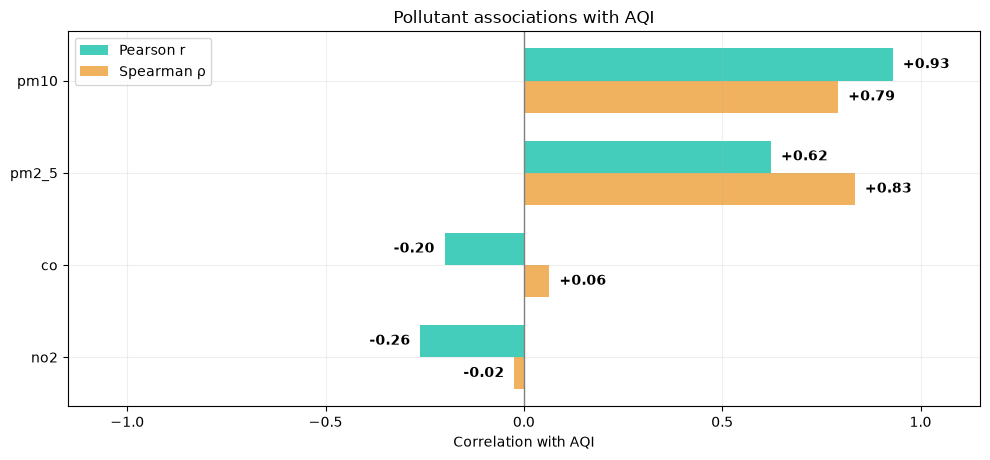

In [44]:
# What this cell does: Define a reusable chart function, then display Pearson and Spearman coefficients for PM10, PM2.5, CO and NO2.
# Expected output: Paired horizontal bars with numeric correlation labels. The chart is saved to visualizations/.


# Define a reusable function for the analysis.
def plot_correlations(fields, title, filename):
    sub = corr_table.loc[fields].iloc[::-1]
    y = np.arange(len(sub))
    h = 0.35

    fig, ax = plt.subplots(figsize=(10, 4.7))

    # Plot Pearson and Spearman correlation bars
    bars1 = ax.barh(
        y + h/2, sub["Pearson r"],
        height=h, label="Pearson r", color="#45cdbc"
    )

    bars2 = ax.barh(
        y - h/2, sub["Spearman rho"],
        height=h, label="Spearman ρ", color="#f0b25e"
    )

    # Add correlation coefficient labels beside each bar
    for bars in [bars1, bars2]:
        for bar in bars:
            value = bar.get_width()
            y_pos = bar.get_y() + bar.get_height() / 2

            if value >= 0:
                x_pos = value + 0.025
                alignment = "left"
            else:
                x_pos = value - 0.025
                alignment = "right"

            ax.text(
                x_pos, y_pos,
                f"{value:+.2f}",
                va="center",
                ha=alignment,
                fontsize=10,
                fontweight="bold"
            )

    # Chart formatting
    ax.set_yticks(y, sub.index)
    ax.axvline(0, color="gray", linewidth=1)

    ax.set(
        xlabel="Correlation with AQI",
        title=title,
        xlim=(-1.15, 1.15)
    )

    ax.legend()
    plt.tight_layout()
    # Save the chart to the visualizations folder.
    save_fig(filename)
    plt.show()


# Step 13: Pollutant correlations with AQI
plot_correlations(
    ["pm10", "pm2_5", "co", "no2"],
    "Pollutant associations with AQI",
    "eda_04_pollutant_correlations"
)

#### Observations:
1. PM10 shows the strongest positive Pearson correlation with AQI (r = 0.930), indicating a strong linear relationship.
2. PM2.5 shows the strongest positive Spearman correlation (ρ = 0.835), indicating a strong monotonic relationship.
3. PM2.5 also has a positive Pearson correlation of 0.623, suggesting that higher PM2.5 concentrations are generally associated with higher AQI.
4. CO shows a weak negative Pearson correlation (-0.200), while NO2 shows a negative Pearson correlation (-0.261).
5. The differences between Pearson and Spearman correlations suggest that some relationships may be nonlinear or influenced by extreme observations.

Conclusion: PM10 and PM2.5 are the pollutants most strongly associated with AQI in this dataset. They are important candidates for further investigation, although correlation alone cannot establish their causal contributions.

#### Step 14 — Plot weather–AQI correlations

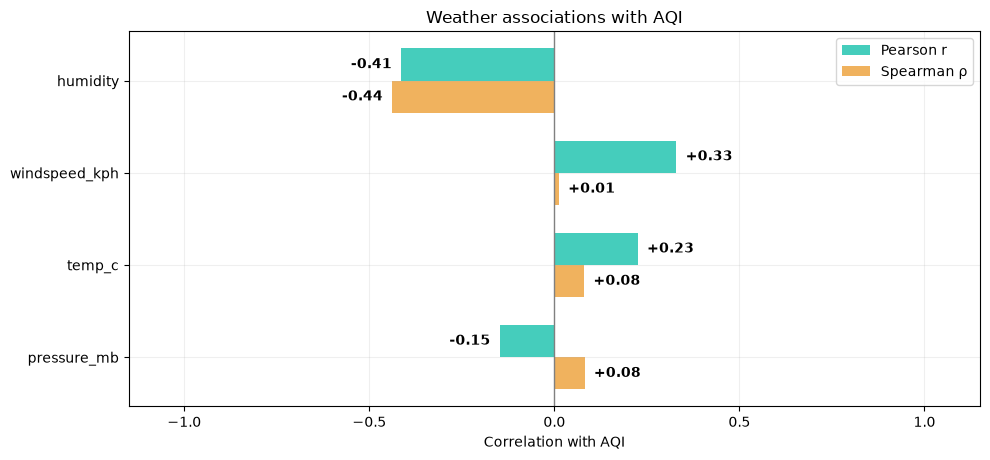

In [45]:
# What this cell does: Reuse the correlation plotting function for humidity, wind speed, temperature and pressure.
# Expected output: Paired correlation bars for weather indicators. The chart is saved to visualizations/.
plot_correlations(["humidity", "windspeed_kph", "temp_c", "pressure_mb"], "Weather associations with AQI", "eda_05_weather_correlations")

#### Observations:
1. Humidity shows a moderate negative correlation with AQI (Pearson = -0.414 and Spearman = -0.438).
2. Wind speed shows a positive Pearson correlation of 0.330, but its Spearman correlation is close to zero (0.012).
3. Temperature shows a weak positive Pearson correlation of 0.225.
4. Atmospheric pressure shows a weak negative Pearson correlation (-0.148) and a very weak positive Spearman correlation (0.082).
5. The differences between the two correlation methods suggest that some weather relationships may be influenced by extreme values or nonlinear patterns.

Conclusion: Humidity has the clearest association with AQI among the weather variables analyzed. However, additional statistical analysis is needed before determining how weather conditions influence air pollution.

#### Step 15 — Explore monthly pollutant and weather patterns

,aqi_index,pm10,pm2_5,humidity,windspeed_kph
month,,,,,
1,188.48,133.89,132.32,84.42,5.68
2,156.54,107.76,66.97,60.98,5.67
3,351.65,435.57,87.05,44.23,7.40
4,416.46,519.86,88.00,24.96,7.12
5,413.25,499.83,97.48,50.81,7.29
6,212.31,299.04,80.67,67.50,6.22
7,150.35,89.09,58.66,80.31,5.11
8,150.27,88.53,57.90,83.23,6.34
9,127.10,86.28,45.19,63.88,7.69


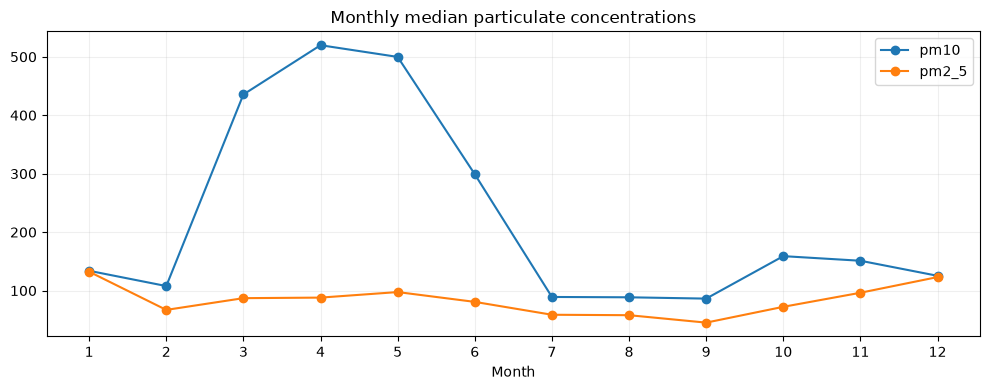

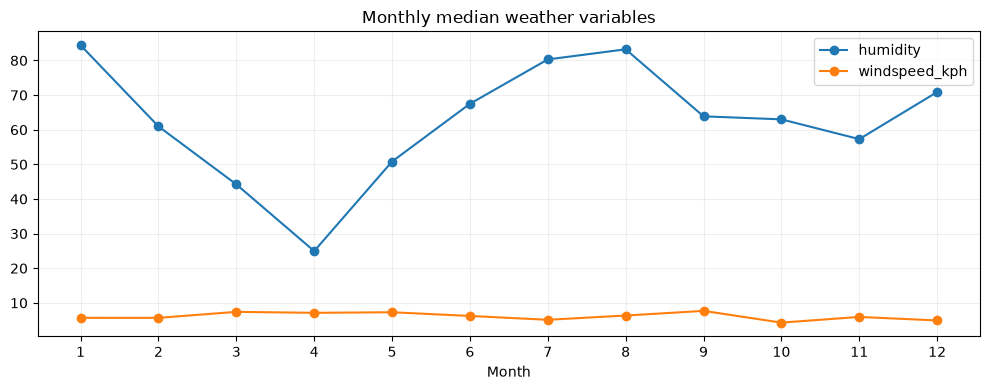

In [46]:
# What this cell does: Compute monthly medians for AQI, particulate matter, humidity and wind speed using one row per profile and date; plot pollutant and weather series.
# Expected output: Monthly median table and two line charts. Both charts are saved to visualizations/.

# Calculate or prepare an intermediate analysis result.
monthly = daily_profiles.groupby("month")[["aqi_index", "pm10", "pm2_5", "humidity", "windspeed_kph"]].median()
# Display the resulting table.
display(monthly.round(2))
# Repeat the following calculation for each item.
for columns, title, filename in [
    (["pm10", "pm2_5"], "Monthly median particulate concentrations", "eda_06_monthly_particulates"),
    (["humidity", "windspeed_kph"], "Monthly median weather variables", "eda_07_monthly_weather"),
]:
    monthly[columns].plot(marker="o", figsize=(10, 4), title=title)
    plt.xlabel("Month"); plt.xticks(range(1,13)); plt.tight_layout()
    # Save the chart to the visualizations folder.
    save_fig(filename)
    plt.show()

#### Observations(Monthly AQI, PM10 and PM2.5 Trends):
1. Monthly median AQI increases sharply from February (156.54) to March (351.65), reaching its highest value in April (416.46).
2. PM10 follows a similar pattern, reaching its highest monthly median concentration in April (519.86).
3. Both AQI and PM10 decline considerably after May, with lower values during July, August, and September.
4. PM2.5 follows a different seasonal pattern. Its monthly median is relatively high in January (132.32) and December (123.13), while the lowest value occurs in September (45.19).
5. The similar movements of AQI and PM10 during spring suggest a strong association between them.

Conclusion: PM10 closely follows the monthly AQI pattern, especially during March–May, while PM2.5 shows a different seasonal trend. These findings support investigating the relative contributions of different pollutants.

#### Observations(Monthly Humidity and Wind Speed Trends):
1. Humidity is highest in January (84.42%) and remains high during July and August.
2. The lowest monthly median humidity occurs in April (24.96%), coinciding with the highest monthly median AQI.
3. Wind speed varies throughout the year, reaching its highest monthly median in September (7.69 km/h).
4. The lowest monthly median wind speed occurs in October (4.29 km/h).
5. The opposite seasonal movements of humidity and AQI during spring are consistent with the negative correlation identified in Step 14.
   
Conclusion: Weather conditions vary considerably across the year. Humidity appears to have a more consistent inverse association with AQI than wind speed in this dataset.

#### Step 16 — Generate a reproducible findings summary

In [47]:
# STEP 16 — Produce a reproducible findings summary
# What this cell does: Extract leading positive Pearson and Spearman variables and print the main dataset, AQI band, out-of-range and seasonal findings.
# Expected output: Text summary and next-step data-quality warning.

# Find the variable with the highest positive Pearson correlation.
top_pearson = corr_table["Pearson r"].idxmax()
# Find the variable with the highest positive Spearman correlation.
top_spearman = corr_table["Spearman rho"].idxmax()
# Print the heading for the final reproducible summary.
print("EDA SUMMARY")
# Report sample size and number of locations.
print("Records:", len(df), "| Locations:", df["location"].nunique())
# Report how many distinct analytical profiles exist.
print("Distinct profile labels:", df["profile"].nunique())
# Report the percentage classified as Moderate.
print("Moderate band:", f"{band_summary.loc['Moderate', 'percent']:.1f}%")
# Report the number and share of out-of-range readings.
print("Above 500:", int(df["above_500"].sum()), f"({df['above_500'].mean():.1%})")
# Report the maximum AQI observed.
print("Maximum AQI:", round(df["aqi_index"].max(), 1))
# Report the leading linear association.
print("Strongest positive Pearson:", top_pearson, round(corr_table.loc[top_pearson, "Pearson r"], 2))
# Report the leading rank association.
print("Strongest positive Spearman:", top_spearman, round(corr_table.loc[top_spearman, "Spearman rho"], 2))
# Report the highest monthly median for Profile B.
print("Profile B in-range median peak:", round(monthly_median["Profile B"].max(), 1))
# Highlight source-validation requirements before drawing policy conclusions.
print("NEXT STEPS: Verify station IDs, source provenance, pollutant units and AQI methodology before location-level decisions.")

EDA SUMMARY
Records: 2190 | Locations: 6
Distinct profile labels: 2
Moderate band: 63.3%
Above 500: 288 (13.2%)
Maximum AQI: 2443.8
Strongest positive Pearson: pm10 0.93
Strongest positive Spearman: pm2_5 0.83
Profile B in-range median peak: 420.6
NEXT STEPS: Verify station IDs, source provenance, pollutant units and AQI methodology before location-level decisions.


#### Final Conclusion
Overall EDA Findings and Our analysis provides three main findings:
- Pollutant association: PM10 and PM2.5 show the strongest positive associations with AQI.
- Seasonal variation: AQI and PM10 are elevated during March–May in the dataset, while PM2.5 shows relatively high values in winter.
- Weather association: Humidity is negatively associated with AQI, while wind speed and temperature show less consistent relationships.